# Hyperparameter search results

This notebook collects the trials of one or more classifier hyperparameter searches and shows how they compare:
which trial is best on every validation metric, how each trial's validation scores developed during training,
whether the trials were still improving when they stopped, how the score depends on each hyperparameter, and
which labels the best trials get wrong most often.

**Data.** Each search is a directory written by `hpc/roihu/hp_search_classifier.sh`
(`results/models/<label type>/<dataset>/hp_search/<search name>/`), with one `trial-NNN/trial.json` per trial.
A trial record holds the sampled hyperparameters, the best validation score, and every validation evaluation
(all metrics of `finetune.py`'s `soft_label_metrics`, per-label accuracy included). Trials are read with
`summarize_hp_search.load_trials`, which refuses to mix trials from different searches (search space, seed,
dataset, objective, input template, training budget).

**How to run.** Run all cells from the `notebooks/` directory, on Roihu or on a machine where the project
directory is mounted. Only small JSON files are read, so the slow sshfs mount is fine. The notebook needs pandas,
NumPy, matplotlib and PyYAML (the local `mwo-local` venv or Roihu's `python-vllm/0.19.1` module), but not torch.

**Common modifications** (all in the parameter cell below):
- *Other searches:* change `SEARCHES`. Searches are shown side by side; each is ranked on its own objective.
- *Batch size against learning rate* (document-budget searches): set `COLOR_BY = "gradient_accumulation_steps"`.
  The learning-rate panel then shows the best learning rate for each batch size.
- *The training-length confound* (epoch-based searches): set `COLOR_BY = "num_train_epochs"`.
- *More highlighted trials:* `TOP_K` is at most 3, because more than three highlight colours can't be told apart
  reliably; the ranking table shows every trial.

## Parameters

`SEARCHES` maps a display name to a search directory. The defaults are the first epoch-based searches on
`hplt-v1` (16 trials per label type, 20,000 training documents each). `COLOR_BY` names the hyperparameter that
colours the effect plots in section 5. It needs at most four distinct values; use `None` for one colour.

In [10]:
from pathlib import Path

# The notebook runs from notebooks/; the repository is its parent.
REPO_ROOT = Path.cwd().resolve().parent

SEARCHES = {
    "topic": REPO_ROOT / "results/models/topic/hplt-v1-topic/hp_search/docs50k",
    "format": REPO_ROOT / "results/models/format/hplt-v1-format/hp_search/docs50k",
}
TOP_K = 3  # trials highlighted in the learning curves (1-3)
COLOR_BY = None  # hyperparameter that colours section 5, or None
PER_LABEL_TRIALS = 3  # best trials shown in the per-label accuracy heatmap
WEAKEST_LABELS = 8  # rows of the weakest-label table

## Setup

Imports, the project modules, and the chart style. Trials are read with the project's own `hp_search` and
`summarize_hp_search` modules, so the notebook and the command-line summary agree on what a search is.

The charts use an explicit light theme (surface, ink and gridline colours set on every element), so they read the
same in any notebook viewer. Colours come from a validated palette:
- the top trials are blue, orange and aqua (distinct for colour-blind readers too);
- all other trials are a recessive gray;
- an ordered hyperparameter is shown light to dark blue.

In [11]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

MODEL_TRAINING = REPO_ROOT / "scripts" / "model_training"
if not (MODEL_TRAINING / "summarize_hp_search.py").is_file():
    raise FileNotFoundError(f"{MODEL_TRAINING} has no summarize_hp_search.py; run the notebook from notebooks/")
sys.path.insert(0, str(MODEL_TRAINING))
import summarize_hp_search  # noqa: E402  (needs the path above)

if not 1 <= TOP_K <= 3:
    raise ValueError(f"TOP_K must be 1-3, got {TOP_K}")

# Chart colours (light theme). SERIES: top trials, validated as a set for colour-vision deficiencies.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, CONTEXT, MISSING = "#e1e0d9", "#c3c2b7", "#c3c2b7", "#f0efec"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
ORDINAL = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # light to dark, for ordered values
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SEQUENTIAL.set_bad(MISSING)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.edgecolor": AXIS,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.labelcolor": INK_2, "font.family": "sans-serif", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
})

# Metric directions, with the same markers finetune.py uses to reject a wrong --greater_is_better.
LOWER_IS_BETTER_MARKERS = ("loss", "divergence", "brier")


def lower_is_better(metric: str) -> bool:
    # True if smaller values of the metric are better.
    return any(marker in metric for marker in LOWER_IS_BETTER_MARKERS)


METRIC_LABELS = {
    "js_divergence_bits": "JS divergence (bits, lower is better)",
    "kl_divergence_bits": "KL divergence (bits, lower is better)",
    "brier_score": "Brier score (lower is better)",
    "accuracy": "Top-label accuracy (higher is better)",
    "accuracy_label_average": "Mean per-label accuracy (higher is better)",
    "accuracy_label_min": "Worst per-label accuracy (higher is better)",
}

## 1. Load the trials

Every search directory is read with `summarize_hp_search.load_trials`. It raises an error if a directory has no
trials, or if its trials differ in search space, seed, dataset, objective, input template or training budget.

Two tables come out of this:
- **`trials`:** one row per trial, with its status, best score, training size and hyperparameters.
- **`evals`:** one row per validation evaluation of a completed trial, with all its metrics.

`documents_seen` is the evaluation's epoch times the number of training documents. That puts epoch-based trials,
step-based trials and different batch sizes on one axis: how much training data the model has seen.

In [12]:
trial_rows, eval_rows = [], []
SEARCH_INFO, PARAMS = {}, {}
for search, path in SEARCHES.items():
    path = Path(path)
    if not path.is_dir():
        raise FileNotFoundError(f"Search {search!r}: directory {path} doesn't exist")
    records = summarize_hp_search.load_trials(path)
    complete = [r for r in records if r["status"] == "complete"]
    if not complete:
        raise ValueError(f"Search {search!r} has no completed trials yet")
    SEARCH_INFO[search] = {
        "directory": path,
        "objective": complete[0]["objective"],
        "greater_is_better": bool(complete[0]["greater_is_better"]),
        "train_documents": sorted({r["train_documents"] for r in complete}),
        "max_train_documents": complete[0].get("max_train_documents"),
        "template": complete[0].get("template"),
    }
    PARAMS[search] = list(dict.fromkeys(name for r in records for name in r["params"]))
    for r in records:
        trial_rows.append({
            "search": search, "trial": r["trial"], "status": r["status"],
            "best_value": r.get("best_value"), "best_step": r.get("best_step"), "best_epoch": r.get("best_epoch"),
            "train_documents": r.get("train_documents"), "effective_batch_size": r.get("effective_batch_size"),
            "train_minutes": r["train_runtime"] / 60 if r.get("train_runtime") is not None else None,
            **{f"param.{name}": value for name, value in r["params"].items()},
        })
        if r["status"] != "complete":
            continue
        if not r["evaluations"]:
            raise ValueError(f"Search {search!r}, trial {r['trial']}: complete but without evaluations")
        for entry in r["evaluations"]:
            if r["objective"] not in entry or not np.isfinite(entry[r["objective"]]):
                raise ValueError(f"Search {search!r}, trial {r['trial']}: evaluation without a finite objective")
            eval_rows.append({
                "search": search, "trial": r["trial"], "step": entry["step"], "epoch": entry["epoch"],
                "documents_seen": entry["epoch"] * r["train_documents"],
                **{key.removeprefix("eval_"): value for key, value in entry.items() if key.startswith("eval_")},
            })

trials = pd.DataFrame(trial_rows)
evals = pd.DataFrame(eval_rows).sort_values(["search", "trial", "step"], ignore_index=True)

overview = pd.DataFrame([
    {
        "search": search,
        "trials": int((trials.search == search).sum()),
        "complete": int(((trials.search == search) & (trials.status == "complete")).sum()),
        "objective": info["objective"].removeprefix("eval_") + (" (higher better)" if info["greater_is_better"] else " (lower better)"),
        "training documents per trial": ", ".join(f"{n:,}" for n in info["train_documents"]),
        "document budget": info["max_train_documents"],
        "input template": repr(info["template"]),
        "searched": ", ".join(PARAMS[search]),
    }
    for search, info in SEARCH_INFO.items()
])
display(overview.style.hide(axis="index"))

unfinished = trials[trials.status != "complete"]
if len(unfinished):
    display(Markdown(
        f"**{len(unfinished)} unfinished trials** (left out below). `running` can also mean the job hit its "
        "time limit: SLURM's kill signal stops the trial before it can record a failure."
    ))
    display(unfinished[["search", "trial", "status"]].style.hide(axis="index"))

search,trials,complete,objective,training documents per trial,document budget,input template,searched
topic,16,16,js_divergence_bits (lower better),"144,145",50000,'{url}\n\n{text}',"learning_rate, gradient_accumulation_steps, weight_decay, warmup_steps, classifier_pooling"
format,16,16,js_divergence_bits (lower better),"144,145",50000,'{url}\n\n{text}',"learning_rate, gradient_accumulation_steps, weight_decay, warmup_steps, classifier_pooling"


## 2. Ranking

Each search's completed trials, ranked by the best value of its objective. Ties keep trial order, as in
`summarize_hp_search.py`. The other metrics are taken at the same evaluation, so each row describes one model
state:
- **Accuracy:** top-label accuracy.
- **Label mean and min:** the mean and the worst of the per-label accuracies.
- **KL and Brier:** the other two distribution measures.

**Bold marks the best value of every metric in each search** (after rounding to the precision shown), whichever
trial has it. A trial can win on the objective and still not be the best on every metric.

In [13]:
SHOWN_METRICS = ["js_divergence_bits", "kl_divergence_bits", "brier_score",
                 "accuracy", "accuracy_label_average", "accuracy_label_min"]
DECIMALS = {"js_divergence_bits": 4, "kl_divergence_bits": 4, "brier_score": 4,
            "accuracy": 3, "accuracy_label_average": 3, "accuracy_label_min": 3}


def best_evaluations(search: str) -> pd.DataFrame:
    # The evaluation each completed trial is scored by: its best_step (trials always record it).
    done = trials[(trials.search == search) & (trials.status == "complete")]
    merged = done.merge(evals[evals.search == search], left_on=["search", "trial", "best_step"],
                        right_on=["search", "trial", "step"], how="left", validate="one_to_one")
    if merged["step"].isna().any():
        raise ValueError(f"Search {search!r}: trials {merged.trial[merged.step.isna()].tolist()} have no "
                         "evaluation at their best_step")
    objective = SEARCH_INFO[search]["objective"].removeprefix("eval_")
    if not np.allclose(merged[objective], merged["best_value"]):
        raise ValueError(f"Search {search!r}: best_value doesn't match the objective at best_step")
    return merged


RANKINGS = {}
for search in SEARCHES:
    ranked = best_evaluations(search).sort_values(
        ["best_value", "trial"], ascending=[not SEARCH_INFO[search]["greater_is_better"], True], kind="stable",
        ignore_index=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    RANKINGS[search] = ranked


def bold_best(column: pd.Series) -> list[str]:
    # Bold every value equal to the column's best after rounding to the shown precision.
    rounded = column.round(DECIMALS[column.name])
    best = rounded.min() if lower_is_better(column.name) else rounded.max()
    return ["font-weight: bold" if value == best else "" for value in rounded]


for search, ranked in RANKINGS.items():
    params = [f"param.{name}" for name in PARAMS[search]]
    table = ranked[["rank", "trial", *SHOWN_METRICS, "best_epoch", "best_step", "documents_seen",
                    "train_minutes", *params]].rename(columns=lambda c: c.removeprefix("param."))
    display(Markdown(f"### {search}"))
    display(
        table.style.hide(axis="index")
        .apply(bold_best, subset=SHOWN_METRICS)
        .format({**{m: f"{{:.{d}f}}" for m, d in DECIMALS.items()}, "best_epoch": "{:.2f}", "best_step": "{:.0f}",
                 "documents_seen": "{:,.0f}", "train_minutes": "{:.0f}", "learning_rate": "{:.3g}",
                 "weight_decay": "{:.3f}", "warmup_steps": "{:.3f}"})
    )

### topic

rank,trial,js_divergence_bits,kl_divergence_bits,brier_score,accuracy,accuracy_label_average,accuracy_label_min,best_epoch,best_step,documents_seen,train_minutes,learning_rate,gradient_accumulation_steps,weight_decay,warmup_steps,classifier_pooling
1,13,0.1086,0.4986,0.1358,0.842,0.773,0.291,0.35,3125,"49,998",22,3.05e-05,2,0.088,0.076,mean
2,11,0.1115,0.5148,0.1398,0.840,0.755,0.073,0.31,1413,"45,214",21,3.87e-05,4,0.009,0.081,cls
3,3,0.1124,0.5222,0.1411,0.840,0.760,0.273,0.35,3125,"49,998",21,1.72e-05,2,0.060,0.036,mean
4,15,0.1136,0.5236,0.1397,0.838,0.759,0.200,0.35,1563,"50,014",21,2.48e-05,4,0.085,0.104,mean
5,7,0.1166,0.5240,0.1435,0.832,0.754,0.218,0.35,782,"50,046",21,2.85e-05,8,0.035,0.015,cls
6,1,0.1173,0.5164,0.1392,0.836,0.762,0.273,0.35,391,"50,046",20,7.55e-05,16,0.092,0.052,cls
7,0,0.1190,0.5303,0.1412,0.842,0.768,0.273,0.35,391,"50,046",20,8.5e-05,16,0.077,0.009,mean
8,5,0.1192,0.5199,0.1413,0.834,0.763,0.255,0.35,391,"50,046",21,6.22e-05,16,0.035,0.056,cls
9,10,0.1205,0.5433,0.1460,0.834,0.761,0.291,0.35,782,"50,046",21,0.000142,8,0.092,0.002,mean
10,6,0.1218,0.5440,0.1458,0.836,0.760,0.291,0.35,391,"50,046",21,6.07e-05,16,0.069,0.060,mean


### format

rank,trial,js_divergence_bits,kl_divergence_bits,brier_score,accuracy,accuracy_label_average,accuracy_label_min,best_epoch,best_step,documents_seen,train_minutes,learning_rate,gradient_accumulation_steps,weight_decay,warmup_steps,classifier_pooling
1,13,0.0760,0.3279,0.0863,0.834,0.732,0.444,0.35,3125,"49,998",21,3.05e-05,2,0.088,0.076,mean
2,11,0.0777,0.3318,0.0890,0.826,0.733,0.444,0.35,1563,"50,014",21,3.87e-05,4,0.009,0.081,cls
3,3,0.0794,0.3448,0.0910,0.824,0.710,0.250,0.35,3125,"49,998",22,1.72e-05,2,0.060,0.036,mean
4,15,0.0812,0.3512,0.0927,0.826,0.714,0.250,0.35,1563,"50,014",21,2.48e-05,4,0.085,0.104,mean
5,7,0.0846,0.3613,0.0959,0.819,0.728,0.444,0.35,782,"50,046",21,2.85e-05,8,0.035,0.015,cls
6,10,0.0850,0.3605,0.0944,0.826,0.710,0.231,0.35,782,"50,046",21,0.000142,8,0.092,0.002,mean
7,1,0.0869,0.3727,0.0992,0.817,0.712,0.389,0.35,391,"50,046",21,7.55e-05,16,0.092,0.052,cls
8,5,0.0870,0.3721,0.0991,0.816,0.714,0.385,0.35,391,"50,046",21,6.22e-05,16,0.035,0.056,cls
9,9,0.0880,0.3760,0.0992,0.822,0.703,0.308,0.35,1563,"50,014",21,0.000136,4,0.003,0.011,mean
10,6,0.0888,0.3825,0.1015,0.812,0.701,0.250,0.35,391,"50,046",21,6.07e-05,16,0.069,0.060,mean


## 3. Learning curves

Validation scores against the number of training documents seen, one column per search. The top row is the
objective, the bottom row top-label accuracy, each on its own axis. The best trials are coloured and labelled at
their last evaluation; all other trials are gray context.

**How to read it.** A coloured curve that is still falling (top) or rising (bottom) at its right end was still
improving when training stopped. More training might have helped it, so its rank partly reflects how long it
trained. Curves that end at different x-values trained on different amounts of data and aren't directly
comparable. In a document-budget search all curves end at the same x.

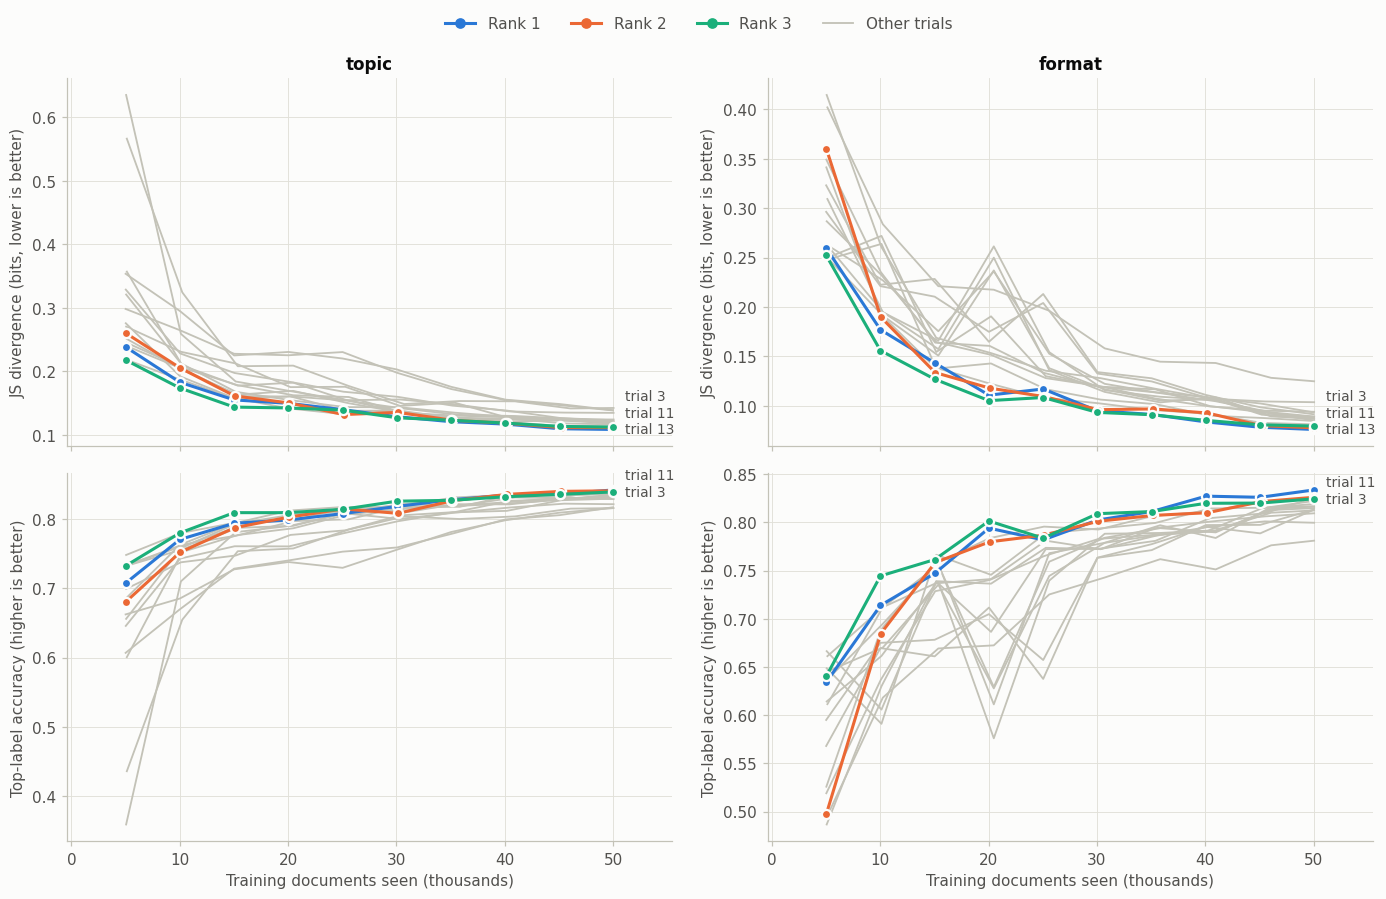

In [14]:
def spread(values: list[float], min_gap: float) -> list[float]:
    # Nudge label positions apart (keeping their order) so end labels don't overlap.
    order = np.argsort(values)
    placed = np.array(values, dtype=float)[order]
    for i in range(1, len(placed)):
        placed[i] = max(placed[i], placed[i - 1] + min_gap)
    result = np.empty_like(placed)
    result[order] = placed
    return result.tolist()


curve_metrics = ["objective", "accuracy"]
fig, axes = plt.subplots(2, len(SEARCHES), figsize=(6.4 * len(SEARCHES), 8.2), squeeze=False, sharex="col")
for col, search in enumerate(SEARCHES):
    objective = SEARCH_INFO[search]["objective"].removeprefix("eval_")
    top = RANKINGS[search].trial.head(TOP_K).tolist()
    search_evals = evals[evals.search == search]
    for row, metric in enumerate([objective, "accuracy"]):
        ax = axes[row][col]
        for trial, group in search_evals.groupby("trial"):
            if trial not in top:
                ax.plot(group.documents_seen / 1000, group[metric], color=CONTEXT, lw=1.2, zorder=1)
        ends = []
        for slot, trial in enumerate(top):
            group = search_evals[search_evals.trial == trial]
            ax.plot(group.documents_seen / 1000, group[metric], color=SERIES[slot], lw=2, marker="o", ms=6,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
            ends.append((trial, group.documents_seen.iloc[-1] / 1000, group[metric].iloc[-1]))
        low, high = ax.get_ylim()
        for (trial, x, _), y in zip(ends, spread([end[2] for end in ends], 0.045 * (high - low))):
            ax.annotate(f"trial {trial}", xy=(x, y), xytext=(8, 0), textcoords="offset points", va="center",
                        color=INK_2, fontsize=9)
        ax.set_ylabel(METRIC_LABELS.get(metric, metric))
        ax.margins(x=0.12)
        if row == 0:
            ax.set_title(search)
        if row == 1:
            ax.set_xlabel("Training documents seen (thousands)")

handles = [Line2D([], [], color=SERIES[slot], lw=2, marker="o", ms=6, label=f"Rank {slot + 1}")
           for slot in range(TOP_K)]
handles.append(Line2D([], [], color=CONTEXT, lw=1.2, label="Other trials"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 4. Were the trials still improving at the end?

For every completed trial:
- **Best at end:** whether its best evaluation was its last one.
- **Last change:** how much the objective changed from the second-to-last to the last evaluation, signed so that
  positive means improvement.

**How to read it.** If most trials, especially the best ones, peak at their last evaluation, the search compared
undertrained models. The ranking then favours the trials that trained longest, not necessarily the best settings.
The fix is a longer training budget, the same for every trial (`TRAIN_DOCUMENTS` in `hp_search_classifier.sh`).

In [15]:
rows = []
for search in SEARCHES:
    objective = SEARCH_INFO[search]["objective"].removeprefix("eval_")
    sign = 1 if SEARCH_INFO[search]["greater_is_better"] else -1
    rank_of = dict(zip(RANKINGS[search].trial, RANKINGS[search]["rank"]))
    for trial, group in evals[evals.search == search].groupby("trial"):
        values = group[objective].to_numpy()
        best_index = int(np.argmax(sign * values))
        rows.append({
            "search": search, "rank": rank_of[trial], "trial": trial, "evaluations": len(values),
            "best evaluation": best_index + 1, "best at end": best_index == len(values) - 1,
            "last change (improvement > 0)": sign * (values[-1] - values[-2]) if len(values) > 1 else np.nan,
        })
improvement = pd.DataFrame(rows).sort_values(["search", "rank"], ignore_index=True)

summary = improvement.groupby("search", sort=False).agg(
    trials=("trial", "size"),
    best_at_end=("best at end", "sum"),
    top_k_best_at_end=("best at end", lambda s: int(s.iloc[:TOP_K].sum())),
).reset_index()
summary["share best at end"] = summary.best_at_end / summary.trials
display(summary.rename(columns={"best_at_end": "best at end", "top_k_best_at_end": f"top {TOP_K} best at end"})
        .style.hide(axis="index").format({"share best at end": "{:.0%}"}))
display(improvement.style.hide(axis="index").format({"last change (improvement > 0)": "{:+.4f}"}))

search,trials,best at end,top 3 best at end,share best at end
format,16,16,3,100%
topic,16,14,2,88%


search,rank,trial,evaluations,best evaluation,best at end,last change (improvement > 0)
format,1,13,10,10,True,+0.0022
format,2,11,10,10,True,+0.0021
format,3,3,10,10,True,+0.0012
format,4,15,10,10,True,+0.0015
format,5,7,10,10,True,+0.0029
format,6,10,10,10,True,+0.0082
format,7,1,10,10,True,+0.0028
format,8,5,10,10,True,+0.0023
format,9,9,10,10,True,+0.0030
format,10,6,10,10,True,+0.0031


## 5. Hyperparameter effects

Each dot is one completed trial: its best objective (y) against one searched hyperparameter (x), one row of
panels per search. Within a row the y-axes are shared, so the panels are directly comparable. Learning rate is on a
log scale. Discrete hyperparameters are spread slightly sideways so that overlapping dots stay visible. The best
trial has a dark ring.

Colour shows `COLOR_BY`, which helps to separate the effect of one setting from another. For example, colour by
temperature to see that the temperature-3.0 trials form their own band, or by batch size to read the learning
rate per batch size.

**Caveat.** With a dozen or so trials and several settings drawn independently, a trend in one panel can come from
another setting. Check it against the colour, and treat a pattern carried by one or two trials as a hint, not a
result.

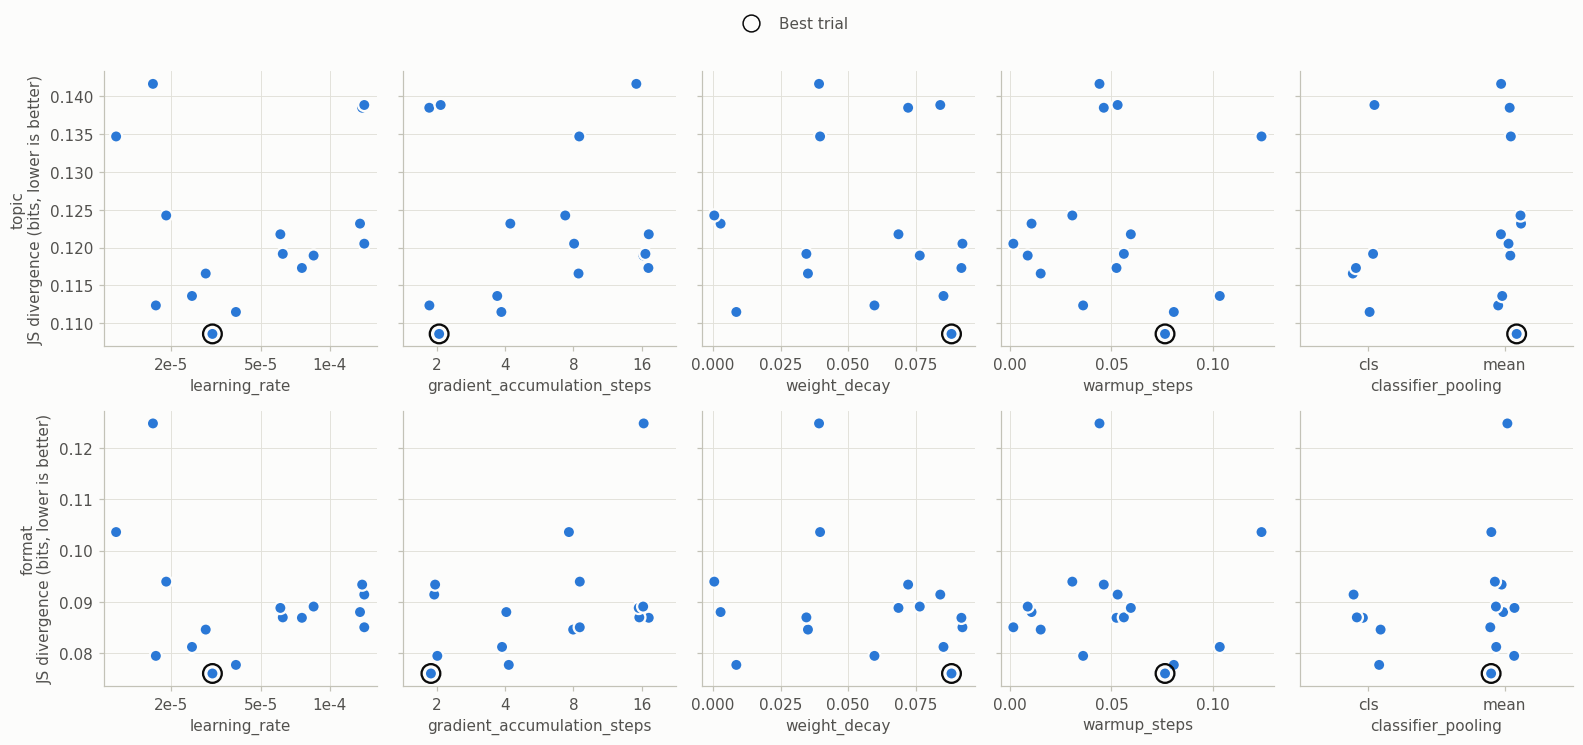

In [16]:
def colour_mapping(search: str):
    # Map each trial to a colour by COLOR_BY; return (colour per trial, legend handles).
    done = RANKINGS[search]
    if COLOR_BY is None or COLOR_BY not in PARAMS[search]:
        return {trial: SERIES[0] for trial in done.trial}, []
    values = done[f"param.{COLOR_BY}"]
    levels = sorted(values.unique(), key=lambda v: (isinstance(v, str), v))
    if len(levels) > 4:
        raise ValueError(f"COLOR_BY={COLOR_BY!r} has {len(levels)} values in search {search!r}; colour can show at "
                         "most 4 (choose a discrete hyperparameter, or None)")
    if all(isinstance(v, str) for v in levels):
        if len(levels) > 3:
            raise ValueError(f"COLOR_BY={COLOR_BY!r} has more than 3 categories in search {search!r}")
        palette = SERIES[: len(levels)]  # unordered categories: categorical colours
    else:
        palette = [ORDINAL[i] for i in np.linspace(0, 3, len(levels)).round().astype(int)]  # ordered: light to dark
    colour_of = dict(zip(levels, palette))
    handles = [Line2D([], [], ls="", marker="o", ms=8, color=colour_of[level], label=f"{COLOR_BY} = {level}")
               for level in levels]
    return dict(zip(done.trial, values.map(colour_of))), handles


ncols = max(len(params) for params in PARAMS.values())
fig, axes = plt.subplots(len(SEARCHES), ncols, figsize=(2.9 * ncols, 3.4 * len(SEARCHES)), squeeze=False,
                         sharey="row")
rng = np.random.default_rng(0)  # fixed jitter, so reruns draw the same picture
legend_handles = {}
for row, search in enumerate(SEARCHES):
    ranked = RANKINGS[search]
    colours, handles = colour_mapping(search)
    for handle in handles:
        legend_handles.setdefault(handle.get_label(), handle)
    best_trial = ranked.trial.iloc[0]
    for col in range(ncols):
        ax = axes[row][col]
        if col >= len(PARAMS[search]):
            ax.set_visible(False)
            continue
        name = PARAMS[search][col]
        values = ranked[f"param.{name}"]
        discrete = values.map(lambda v: isinstance(v, str)).all() or values.nunique() <= 6
        if discrete:
            levels = sorted(values.unique(), key=lambda v: (isinstance(v, str), v))
            x = values.map({level: i for i, level in enumerate(levels)}) + rng.uniform(-0.12, 0.12, len(values))
            ax.set_xticks(range(len(levels)), [str(level) for level in levels])
            ax.set_xlim(-0.5, len(levels) - 0.5)
            ax.grid(axis="x", visible=False)
        else:
            x = values
            if name == "learning_rate":
                ax.set_xscale("log")
                ticks = [t for t in (1e-5, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4) if values.min() / 1.5 <= t <= values.max() * 1.5]
                ax.set_xticks(ticks, [f"{t:.0e}".replace("e-0", "e-") for t in ticks])
                ax.minorticks_off()
        ax.scatter(x, ranked.best_value, s=64, c=[colours[t] for t in ranked.trial], edgecolors=SURFACE,
                   linewidths=1.5, zorder=3)
        is_best = (ranked.trial == best_trial).to_numpy()
        ax.scatter(np.asarray(x)[is_best], ranked.best_value[is_best], s=150, facecolors="none", edgecolors=INK,
                   linewidths=1.5, zorder=4)
        ax.set_xlabel(name)
        if col == 0:
            objective = SEARCH_INFO[search]["objective"].removeprefix("eval_")
            ax.set_ylabel(f"{search}\n" + METRIC_LABELS.get(objective, objective))

handles = list(legend_handles.values())
handles.append(Line2D([], [], ls="", marker="o", ms=11, markerfacecolor="none", markeredgecolor=INK,
                      label="Best trial"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 6. Per-label accuracy of the best trials

Per-label accuracy is the recall of each label: the share of validation documents whose LLM top label is that
label and that the classifier also ranks first. It is taken at each trial's best evaluation. The heatmap shows the
best `PER_LABEL_TRIALS` trials of each search, with labels sorted from the best trial's weakest to its strongest.
Darker is better; the colour scale starts at the lowest value shown, not at 0. Gray cells are labels that were never the top label in the validation set (the training code
reports no accuracy for them). The table after the heatmap gives the exact values of the weakest labels.

**Caveat.** `trial.json` doesn't store how many validation documents each label has, so a rare label's accuracy
can rest on a handful of documents. Check the support in `predictions.jsonl` of a full training run before
drawing conclusions about a single label.

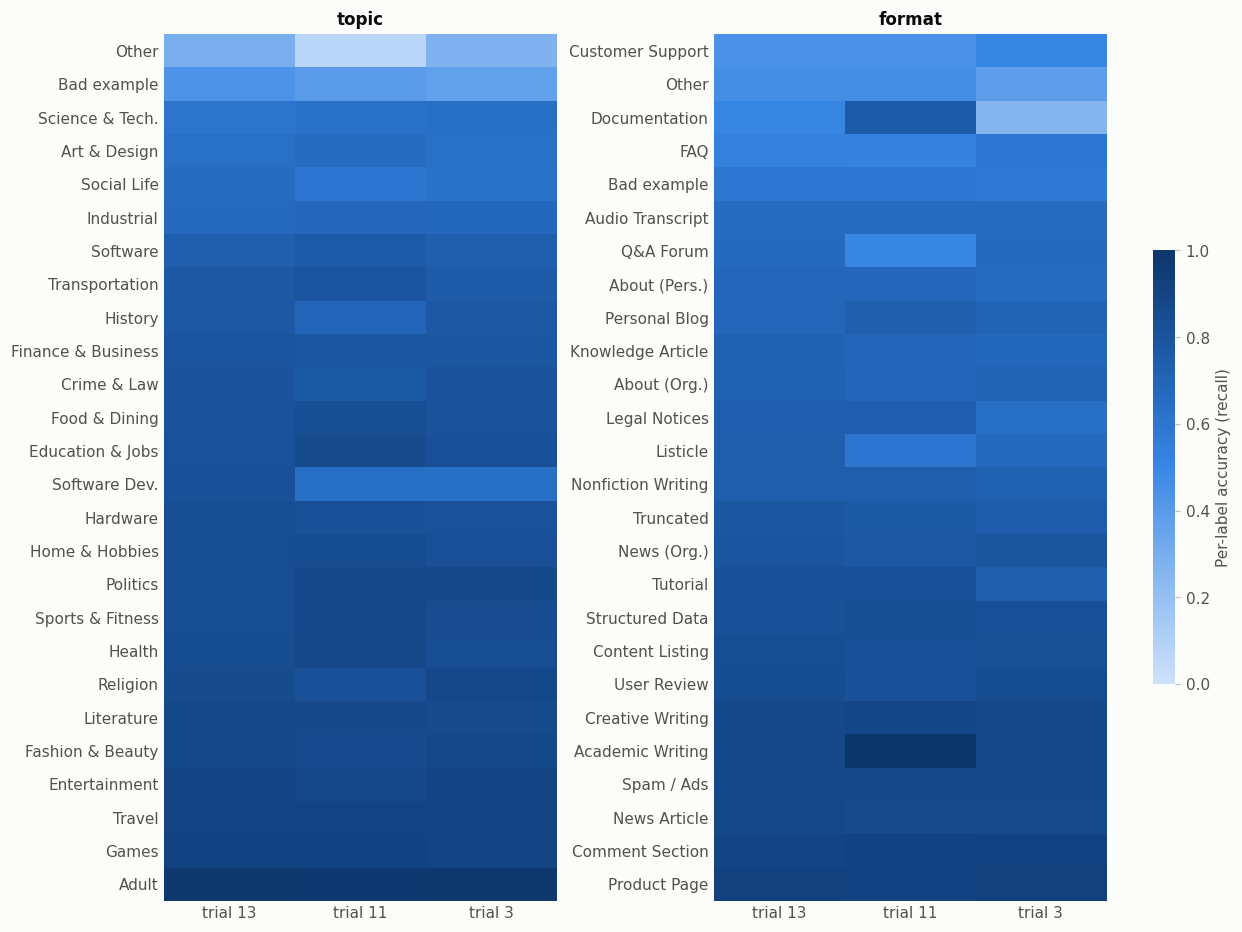

**topic: the 8 weakest labels of the best trial**

,trial 13 (rank 1),trial 11 (rank 2),trial 3 (rank 3)
Other,0.291,0.073,0.273
Bad example,0.435,0.391,0.370
Science & Tech.,0.606,0.620,0.634
Art & Design,0.632,0.655,0.632
Social Life,0.653,0.600,0.621
Industrial,0.661,0.684,0.672
Software,0.733,0.760,0.733
Transportation,0.767,0.791,0.750


**format: the 8 weakest labels of the best trial**

,trial 13 (rank 1),trial 11 (rank 2),trial 3 (rank 3)
Customer Support,0.444,0.444,0.500
Other,0.462,0.462,0.385
Documentation,0.500,0.750,0.250
FAQ,0.529,0.529,0.588
Bad example,0.590,0.583,0.577
Audio Transcript,0.655,0.655,0.655
Q&A Forum,0.667,0.500,0.667
About (Pers.),0.686,0.686,0.657


In [17]:
def label_accuracy(search: str) -> pd.DataFrame:
    # Labels x best trials: per-label accuracy at the best evaluation, labels sorted weakest first.
    ranked = RANKINGS[search].head(PER_LABEL_TRIALS)
    columns = [c for c in ranked.columns if c.startswith("accuracy__")]
    table = ranked.set_index("trial")[columns].T
    table = table.dropna(how="all")  # labels of the other taxonomy, or never a top label here
    table.index = table.index.str.removeprefix("accuracy__")
    table.columns = [f"trial {trial} (rank {rank})" for trial, rank in zip(ranked.trial, ranked["rank"])]
    return table.sort_values(table.columns[0], na_position="last")


tables = {search: label_accuracy(search) for search in SEARCHES}
# The scale starts at the lowest value shown (rounded down to 0.1), so the differences between labels stay visible.
vmin = np.floor(min(np.nanmin(t.to_numpy(dtype=float)) for t in tables.values()) * 10) / 10
height = 0.26 * max(len(t) for t in tables.values()) + 1.6
fig, axes = plt.subplots(1, len(SEARCHES), figsize=(5.6 * len(SEARCHES), height), squeeze=False,
                         layout="constrained")
for ax, (search, table) in zip(axes[0], tables.items()):
    image = ax.imshow(np.ma.masked_invalid(table.to_numpy(dtype=float)), cmap=SEQUENTIAL, vmin=vmin, vmax=1,
                      aspect="auto")
    ax.set_yticks(range(len(table)), table.index)
    ax.set_xticks(range(table.shape[1]), [c.split(" (")[0] for c in table.columns], rotation=0)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(search)
colourbar = fig.colorbar(image, ax=axes[0].tolist(), shrink=0.5)
colourbar.set_label("Per-label accuracy (recall)", color=INK_2)
colourbar.outline.set_visible(False)
plt.show()

for search, table in tables.items():
    display(Markdown(f"**{search}: the {WEAKEST_LABELS} weakest labels of the best trial**"))
    display(table.head(WEAKEST_LABELS).style.format("{:.3f}", na_rep="n/a"))

## 7. Check against `summarize_hp_search.py`

The command-line summary writes `summary.tsv` into each search directory. This cell compares its ranking with the
notebook's ranking: the same trials in the same order with the same best values.

A mismatch usually means `summary.tsv` is older than the trials, for example when trials finished after the
summary was written; rerun `summarize_hp_search.py` to refresh it. The last line gives the best trial's settings
as flags for the final training run, exactly as the summary script prints them.

In [18]:
for search, ranked in RANKINGS.items():
    path = SEARCH_INFO[search]["directory"] / "summary.tsv"
    display(Markdown(f"### {search}"))
    if not path.is_file():
        display(Markdown(f"No `{path.name}` yet; run `summarize_hp_search.py {path.parent}` to create it."))
    else:
        reported = pd.read_csv(path, sep="\t")
        objective = SEARCH_INFO[search]["objective"]
        comparison = pd.DataFrame({
            "rank": ranked["rank"],
            "trial (notebook)": ranked.trial,
            "trial (summary.tsv)": reported.trial.reindex(ranked.index),
            "best value (notebook)": ranked.best_value,
            "best value (summary.tsv)": reported[objective].reindex(ranked.index),
        })
        comparison["match"] = (comparison["trial (notebook)"] == comparison["trial (summary.tsv)"]) & np.isclose(
            comparison["best value (notebook)"], comparison["best value (summary.tsv)"].astype(float))
        mismatches = int((~comparison.match).sum()) + abs(len(reported) - len(ranked))
        verdict = ("matches the notebook" if mismatches == 0 else
                   f"**differs in {mismatches} rows; it is probably out of date, so rerun summarize_hp_search.py**")
        display(Markdown(f"`summary.tsv` ({len(reported)} trials) {verdict}."))
        display(comparison.style.hide(axis="index").format(
            {"best value (notebook)": "{:.5f}", "best value (summary.tsv)": "{:.5f}"}))
    best = ranked.iloc[0]
    params = {name: best[f"param.{name}"] for name in PARAMS[search]}
    display(Markdown(f"Best trial {best.trial}; flags for `train_classifier.sh`: "
                     f"`{summarize_hp_search.as_flags(params)}`"))

### topic

No `summary.tsv` yet; run `summarize_hp_search.py /home/otto-tarkka/mnt/roihu-0507/MultilingualWebOrganizer/results/models/topic/hplt-v1-topic/hp_search/docs50k` to create it.

Best trial 13; flags for `train_classifier.sh`: `--learning_rate 3.05e-05 --gradient_accumulation_steps 2 --weight_decay 0.088284 --warmup_steps 0.076468 --classifier_pooling mean`

### format

No `summary.tsv` yet; run `summarize_hp_search.py /home/otto-tarkka/mnt/roihu-0507/MultilingualWebOrganizer/results/models/format/hplt-v1-format/hp_search/docs50k` to create it.

Best trial 13; flags for `train_classifier.sh`: `--learning_rate 3.05e-05 --gradient_accumulation_steps 2 --weight_decay 0.088284 --warmup_steps 0.076468 --classifier_pooling mean`